# Parte 6 – Descriptores y benigno vs. maligno

Con la lesión delimitada, la última pregunta del trabajo: **¿qué rasgos de la lesión diferencian las benignas de las malignas?** Cuantificamos los rasgos que el radiólogo evalúa a ojo con el léxico **BI-RADS** (forma, orientación, margen, ecogenicidad, rasgos posteriores) y la textura interna, y medimos cuáles separan las dos clases.

**Qué viene de las partes anteriores:**
- Parte 0: las malignas son **más grandes** y tienen **menos contraste** con el tejido que las rodea (ecogenicidad relativa candidata a descriptor). BUSI tiene **imágenes casi repetidas**, y 17 imágenes con varias máscaras.
- Parte 2: el tejido de las malignas tiene μ/σ **más alto incluso lejos de la lesión**, con el mismo brillo: puede ser un efecto de la adquisición. Por eso agregamos descriptores de textura **relativos al tejido de la misma imagen**.
- Parte 3: la GLCM con **cuantización fija** (`dominios.glcm_region`) permite comparar valores entre imágenes. La cuantización por recorte de la Parte 4 no (cada imagen tiene su propia escala).
- Parte 5: tenemos la segmentación propia de las 647 imágenes, para comparar los descriptores con la máscara manual y con la segmentación.

**Hipótesis del anteproyecto:** las malignas tienen forma más irregular (menor circularidad y solidez), orientación "más alta que ancha" y textura interna más heterogénea.

**Contenido**
1. Qué lesión describimos (imágenes con varias máscaras)
2. Imágenes casi duplicadas
3. Los descriptores
4. Diferencias entre clases: Mann-Whitney con corrección de Holm y *boxplots*
5. Clasificador: regresión logística con validación cruzada agrupada
6. Máscara manual vs. segmentación propia
7. Conclusiones

### Preparación

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'src'))

%load_ext autoreload
%autoreload 2

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.stats import spearmanr, wilcoxon
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import StratifiedKFold
from joblib import Parallel, delayed

from busi.datos import listar_casos, cargar_caso, cargar_imagen
from busi.config import load_config
from busi import artefactos, dominios, segmentacion, descriptores

warnings.filterwarnings("ignore", category=FutureWarning)
cfg = load_config()
SEED = cfg["SEED"]
CARPETA = cfg["OUTPUT_DIR"] / "descriptores"
CARPETA.mkdir(parents=True, exist_ok=True)

def cargar_limpio(caso):
    # Imagen sin marcas del ecógrafo (Parte 1), máscara de la lesión y máscara de las marcas reconstruidas.
    img, mascara = cargar_caso(caso)
    img, marcas = artefactos.limpiar(img)
    return img, mascara, marcas

casos = listar_casos().set_index("id")
con_lesion = casos[casos["clase"] != "normal"]
print(f"{len(con_lesion)} imágenes con lesión: {(con_lesion['clase'] == 'benign').sum()} benignas, "
      f"{(con_lesion['clase'] == 'malignant').sum()} malignas")

647 imágenes con lesión: 437 benignas, 210 malignas


## 1. Qué lesión describimos

En la Parte 0 vimos 17 imágenes con más de un archivo de máscara (16 benignas, 1 maligna). En la Parte 5 contamos **34 imágenes con más de una componente conexa**: 15 de esas 17 (en las otras 2 las máscaras se tocan) y 19 máscaras de un solo archivo con manchas sueltas. Hay tres opciones:

| Opción | Problema |
|---|---|
| Unir todas las componentes (lo que hace `cargar_caso`) | Los descriptores de **forma** dejan de describir una lesión: dos nódulos redondos separados dan solidez y circularidad bajas, como si fueran **una** lesión irregular. Eso empujaría a esas benignas hacia "maligna". |
| Describir cada lesión por separado | Una imagen aportaría varias filas casi iguales en adquisición y tejido, que no son independientes (el mismo problema de los duplicados), y las 16 benignas pesarían doble. |
| **Quedarse con una lesión por imagen** | Se pierde la información de las lesiones secundarias. |

**Decisión:** describimos **una lesión por imagen**, la **lesión principal** de la Parte 5 (`segmentacion.lesion_principal`): la componente conexa que contiene la semilla, el punto más interior de la máscara. Es la misma lesión que segmentamos en la Parte 5, así que la comparación manual vs. segmentación (sección 6) mide lo mismo. Y BI-RADS describe lesión por lesión, no el conjunto.

Verificamos qué se pierde: qué fracción del área marcada queda fuera de la lesión principal.

In [3]:
filas = []
for id_caso, caso in con_lesion.iterrows():
    _, mascara = cargar_caso(caso)
    n = segmentacion.measure.label(mascara, connectivity=2).max()
    if n > 1:
        principal = segmentacion.lesion_principal(mascara)
        filas.append({"id": id_caso, "clase": caso["clase"], "componentes": n, "archivos": caso["n_mascaras"],
                      "% del área fuera de la principal": 100 * (1 - principal.sum() / mascara.sum())})
multi = pd.DataFrame(filas).set_index("id")
print(f"{len(multi)} imágenes con más de una componente ({(multi['clase'] == 'malignant').sum()} malignas)")
print(multi.groupby(multi["archivos"] > 1)["% del área fuera de la principal"].describe().round(1)
      .rename(index={False: "un archivo (manchas sueltas)", True: "varios archivos (varias lesiones)"}))

34 imágenes con más de una componente (10 malignas)
                                   count  mean   std  min   25%   50%   75%  \
archivos                                                                      
un archivo (manchas sueltas)        19.0   0.0   0.0  0.0   0.0   0.0   0.0   
varios archivos (varias lesiones)   15.0  29.0  17.9  3.6  16.7  23.9  44.0   

                                    max  
archivos                                 
un archivo (manchas sueltas)        0.0  
varios archivos (varias lesiones)  58.2  


**Qué vemos:**
- En las **19 máscaras de un solo archivo** con varias componentes, lo que queda fuera de la lesión principal es **prácticamente nada** (0,0 % del área): son manchitas de pocos píxeles del dibujo. Quedarse con la principal solo las limpia.
- En las **15 imágenes con varias lesiones** se deja afuera en promedio el **29 %** del área marcada (de 4 % a 58 %). Es información que se pierde, pero son 15 imágenes de 647: no puede cambiar las conclusiones.

## 2. Imágenes casi duplicadas

En las Partes 0 y 1 vimos que BUSI tiene imágenes **casi repetidas**: la misma escena con otro recorte (`benign (52)` y `benign (134)`), o tomas muy parecidas de la misma lesión. Para la estadística descriptiva (sección 4) son un problema menor, pero para el **clasificador** son graves: si una imagen está en el entrenamiento y su casi-gemela en la prueba, el modelo "reconoce" la imagen en vez de aprender a distinguir clases, y el resultado queda inflado.

**Cómo las detectamos.** Cada imagen se reduce a 64 × 64 px (`descriptores.huella`): así desaparecen el *speckle* y las diferencias chicas de recorte. Después se compara cada par de imágenes con la **correlación de Pearson** de sus huellas.

Pero toda ecografía tiene el mismo patrón general (piel clara arriba, tejido más oscuro abajo), así que dos imágenes **sin ninguna relación** ya se correlacionan alto. Por eso, antes de correlacionar, a la huella le restamos su versión suavizada (gaussiano de σ = 4 px en la imagen de 64 × 64): queda la **estructura** de la imagen (dónde están la lesión, las capas, las fibras) y no la tendencia "claro arriba, oscuro abajo". Lo verificamos comparando las dos versiones. Comparamos las **780 imágenes** (las normales también pueden ser tomas de las mismas pacientes).

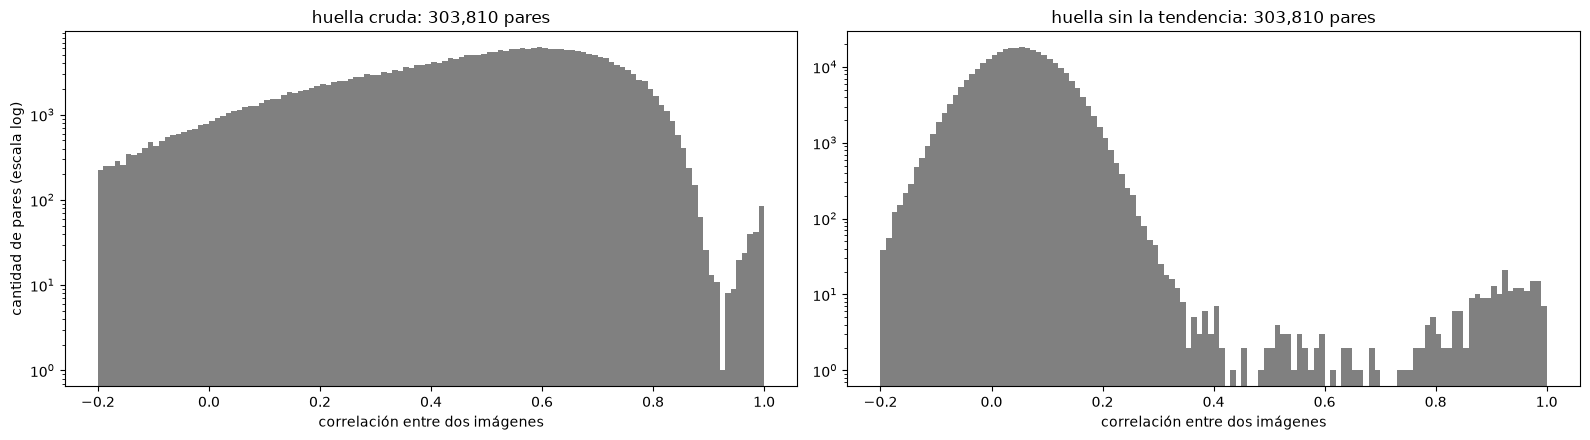

Mediana de la correlación entre pares: cruda 0.51, sin tendencia 0.05


In [4]:
def huellas(sin_tendencia):
    H = []
    for _, caso in casos.iterrows():
        img = cargar_imagen(caso["ruta"])
        H.append(descriptores.huella(img, sin_tendencia=sin_tendencia))
    return np.array(H)

ids = casos.index.to_numpy()
clase = casos["clase"].to_numpy()
corr_cruda = descriptores.matriz_correlacion(huellas(False))
corr = descriptores.matriz_correlacion(huellas(True))
arriba = np.triu_indices(len(ids), 1)          # cada par una sola vez

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, c, titulo in [(axes[0], corr_cruda, "huella cruda"), (axes[1], corr, "huella sin la tendencia")]:
    ax.hist(c[arriba], bins=np.linspace(-0.2, 1, 121), color="gray", log=True)
    ax.set_xlabel("correlación entre dos imágenes")
    ax.set_title(f"{titulo}: {len(arriba[0]):,} pares")
axes[0].set_ylabel("cantidad de pares (escala log)")
plt.tight_layout()
plt.show()
print(f"Mediana de la correlación entre pares: cruda {np.median(corr_cruda[arriba]):.2f}, sin tendencia {np.median(corr[arriba]):.2f}")

**Qué vemos:** con la huella cruda, la mitad de los pares tiene correlación > 0,51 aunque no tengan nada que ver: el patrón general de la ecografía domina. Sin la tendencia, la mediana baja a **0,05** (imágenes no relacionadas ≈ sin correlación) y queda una **cola** de pocos pares con correlación alta: los candidatos a casi-duplicados.

### 2.1 Elegir el umbral

¿A partir de qué correlación dos imágenes son "la misma escena"? Usamos una pista que no depende de mirar las imágenes: la **clase**. Si dos imágenes no tienen nada que ver, la probabilidad de que sean de la misma clase es la del azar: (437² + 210² + 133²) / 780² ≈ 41 %. Si son tomas de la misma lesión, tienen que ser de la **misma** clase. Miramos, por rangos de correlación, qué porcentaje de pares es de la misma clase:

In [5]:
valores = corr[arriba]
misma = clase[arriba[0]] == clase[arriba[1]]
bordes = [-1, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.7, 0.9, 1.01]
tabla = pd.DataFrame({"rango": pd.cut(valores, bordes, right=False), "misma clase": misma})
tabla = tabla.groupby("rango", observed=True)["misma clase"].agg(pares="size", misma_clase=lambda s: 100 * s.mean())
tabla.round(1)

,pares,misma_clase
rango,,
"[-1.0, 0.2)",299839,41.3
"[0.2, 0.25)",3135,46.0
"[0.25, 0.3)",488,52.5
"[0.3, 0.35)",79,82.3
"[0.35, 0.4)",19,84.2
"[0.4, 0.5)",15,93.3
"[0.5, 0.7)",34,94.1
"[0.7, 0.9)",74,94.6
"[0.9, 1.01)",127,95.3


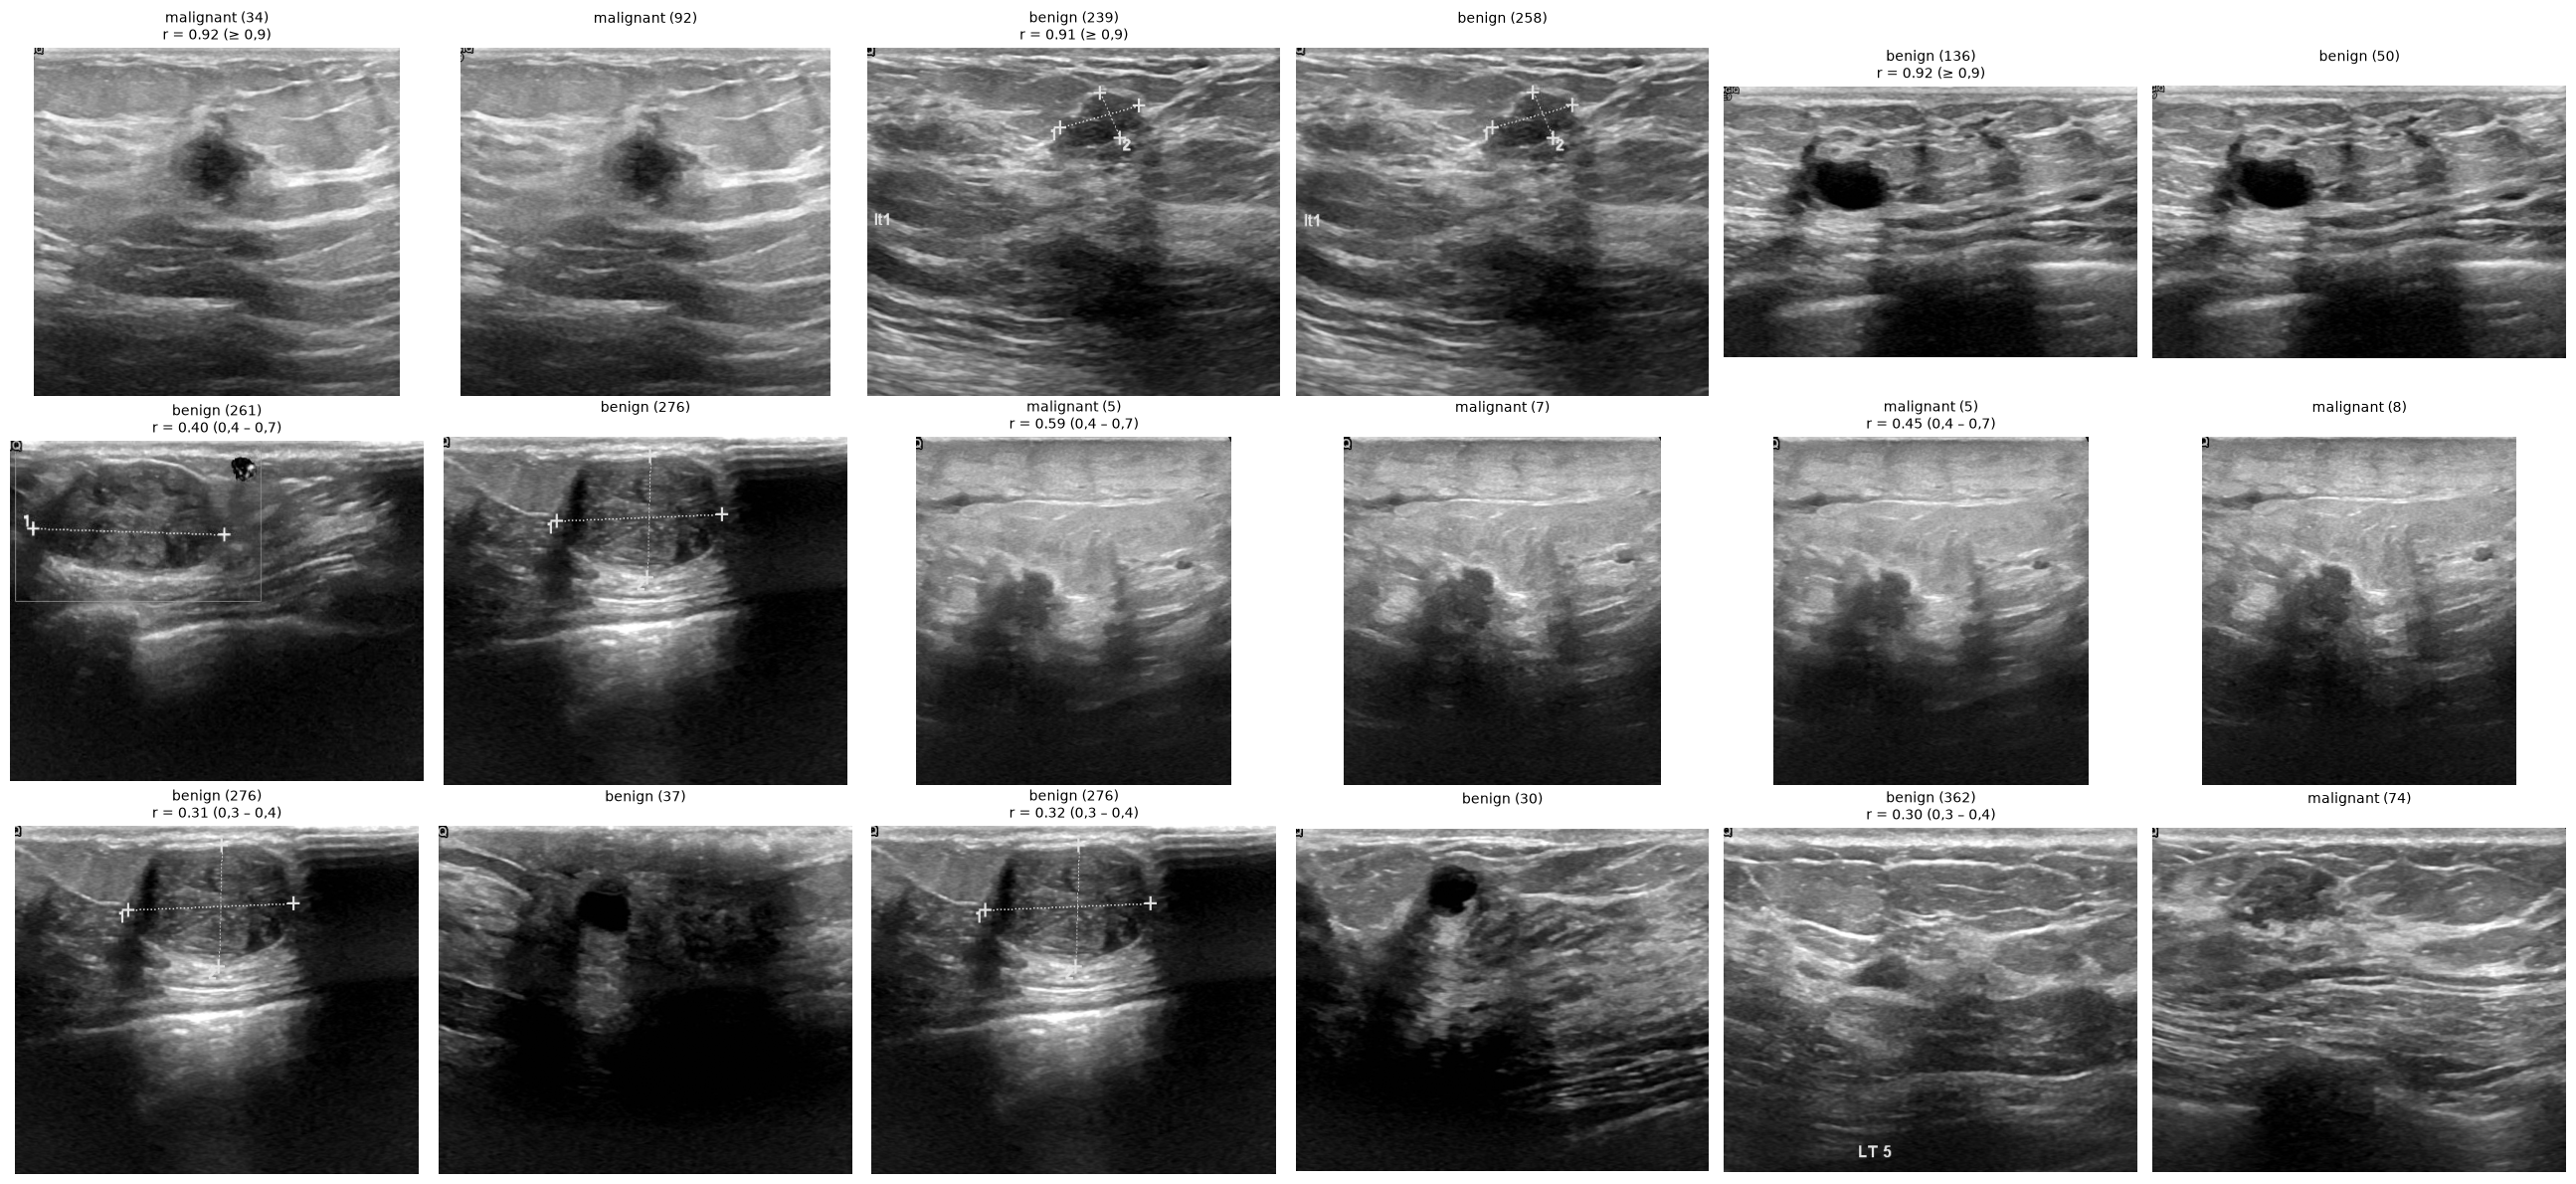

In [6]:
UMBRAL = 0.4
pares_ej = {"≥ 0,9": [], "0,4 – 0,7": [], "0,3 – 0,4": []}
orden = np.argsort(-valores)
rng = np.random.default_rng(SEED)
for nombre, (lo, hi) in zip(pares_ej, [(0.9, 1.01), (0.4, 0.7), (0.3, 0.4)]):
    candidatos = [k for k in orden if lo <= valores[k] < hi]
    pares_ej[nombre] = [candidatos[k] for k in rng.choice(len(candidatos), 3, replace=False)]

fig, axes = plt.subplots(3, 6, figsize=(26, 12))
for fila, (nombre, ks) in zip(axes, pares_ej.items()):
    for j, k in enumerate(ks):
        for m, idx in enumerate([arriba[0][k], arriba[1][k]]):
            ax = fila[2 * j + m]
            ax.imshow(cargar_imagen(casos.iloc[idx]["ruta"]), cmap="gray")
            ax.set_title(f"{ids[idx]}" + (f"\nr = {valores[k]:.2f} ({nombre})" if m == 0 else "\n"), fontsize=10)
            ax.axis("off")
plt.tight_layout()
plt.show()

**Qué vemos:**
- Por debajo de 0,2 el 41 % de los pares es de la misma clase: **exactamente el azar**. Ahí no hay relación entre las imágenes.
- Entre 0,2 y 0,3 sube apenas (46–52 %). **Desde 0,3 salta** a 82–84 %, y **desde 0,4 llega al 93–95 %**: casi todos los pares son de la misma clase, como se espera si son tomas de la misma lesión.
- En los ejemplos, los pares con r ≥ 0,9 son **la misma imagen** (a veces con otro recorte o con *calipers* agregados). Entre 0,4 y 0,7 son **tomas distintas de la misma lesión** (`malignant (5)`, `(7)` y `(8)`: mismo nódulo, mismo tejido, apenas corrido). Entre 0,3 y 0,4 ya son lesiones distintas, aunque a veces de anatomía parecida (quizás la misma paciente).

Elegimos **0,4**: ahí la fracción de la misma clase ya está en su máximo y, como vemos abajo, no se forman cadenas que junten imágenes sin relación (con 0,3 aparece un grupo de 20 imágenes encadenadas).

In [7]:
grupo_780 = descriptores.grupos_duplicados(corr, UMBRAL)
grupos = pd.Series(grupo_780, index=ids, name="grupo")
tam = grupos.map(grupos.value_counts())
print(f"Umbral {UMBRAL}: {grupos.nunique()} grupos para {len(ids)} imágenes; "
      f"{(tam > 1).sum()} imágenes en {grupos[tam > 1].nunique()} grupos de 2 o más (el más grande tiene {tam.max()})")

mixtos = [g for g, d in casos.groupby(grupos)["clase"] if d.nunique() > 1]
print(f"Grupos con imágenes de clases distintas: {len(mixtos)}")
for g in mixtos:
    print("   ", ", ".join(grupos.index[grupos == g]))

grupos_lesion = grupos.loc[con_lesion.index]
print(f"\nEntre las {len(con_lesion)} imágenes con lesión: {grupos_lesion.nunique()} grupos; "
      f"{(grupos_lesion.map(grupos_lesion.value_counts()) > 1).sum()} imágenes tienen al menos una casi-duplicada")
grupos.to_csv(CARPETA / "grupos_duplicados.csv")

Umbral 0.4: 589 grupos para 780 imágenes; 335 imágenes en 144 grupos de 2 o más (el más grande tiene 7)
Grupos con imágenes de clases distintas: 7
    benign (131), benign (42), malignant (51)
    benign (164), benign (85), malignant (52)
    benign (269), normal (1)
    benign (333), malignant (77), malignant (78)
    benign (399), benign (406), malignant (93), malignant (94)
    benign (433), benign (435), malignant (145)
    benign (437), normal (34)

Entre las 647 imágenes con lesión: 498 grupos; 264 imágenes tienen al menos una casi-duplicada


**Qué vemos:**
- **335 de las 780 imágenes** (43 %) tienen al menos una casi-duplicada; forman 144 grupos de 2 a 7 imágenes. Entre las 647 con lesión, **264 imágenes** están en algún grupo: las 647 imágenes son en realidad **498 escenas distintas**.
- **7 grupos mezclan clases.** El caso más claro es `benign (433)` y `malignant (145)`, con correlación 1,00: **la misma imagen con dos diagnósticos distintos**. Es un error del dataset (o dos lesiones distintas en la misma toma, cada una con su clase), y no podemos saber cuál es la etiqueta correcta. Los dejamos, pero agrupados: nunca van a estar una en entrenamiento y la otra en prueba.

Los grupos se guardan en `outputs/descriptores/grupos_duplicados.csv`.

## 3. Los descriptores

`descriptores.descriptores_caso()` calcula, para una lesión, tres familias de descriptores. Todos se calculan sobre la imagen limpia (sin marcas) y sin usar los píxeles reconstruidos por *inpainting*.

**Forma** (`descriptores_forma`, sobre la máscara):

| Descriptor | Qué mide | Rasgo BI-RADS |
|---|---|---|
| `area` | Tamaño en píxeles (no conocemos los mm por píxel) | — |
| `alto_ancho` | Alto / ancho del rectángulo que la contiene | Orientación: > 1 es "más alta que ancha", sospechosa |
| `circularidad` | 4π·área / perímetro² (1 = círculo) | Forma y margen |
| `solidez` | Área / área de su envolvente convexa (1 = convexa) | Forma: entrantes, lóbulos |
| `excentricidad` | Qué tan alargada es la elipse equivalente (0 = círculo) | Forma ovalada vs. redonda |
| `irregularidad` | Desvío / media de la distancia del contorno al centro (0 = círculo) | Margen no circunscripto, espiculado |

**Intensidad** (`descriptores_intensidad`):

| Descriptor | Qué mide | Rasgo BI-RADS |
|---|---|---|
| `media`, `desvio` | Brillo y su variación dentro de la lesión | Ecogenicidad, heterogeneidad |
| `ecogenicidad` | Media de la lesión / media del **anillo** de tejido (5 a 20 px por fuera, el de las Partes 3 y 4) | Ecogenicidad relativa: < 1 hipoecoica |
| `sombra` | Media **debajo** de la lesión / media del tejido **lateral a la misma profundidad** | Rasgos posteriores: < 1 sombra (sospechosa), > 1 refuerzo (quistes) |

La sombra compara con el tejido a la misma profundidad porque el brillo de la ecografía depende de la profundidad (el sonido se atenúa al atravesar tejido, y el equipo lo compensa con una ganancia que crece con la profundidad): comparar con el tejido de arriba confundiría la sombra con ese efecto.

**Textura** (`descriptores_textura`): GLCM dentro de la lesión con `dominios.glcm_region` (la de la Parte 3): **cuantización fija** a 32 niveles (los mismos cortes de gris en todas las imágenes), solo pares con los dos píxeles dentro de la lesión, promedio de las 4 direcciones, distancias 1 y 4 px. Contraste, homogeneidad, energía y correlación. Y cada una también **relativa** al anillo de tejido de la misma imagen (`_rel`: cociente lesión / anillo; para la correlación, que puede valer 0 o ser negativa, la diferencia), por el efecto de adquisición de la Parte 2.

Las regiones en un ejemplo:

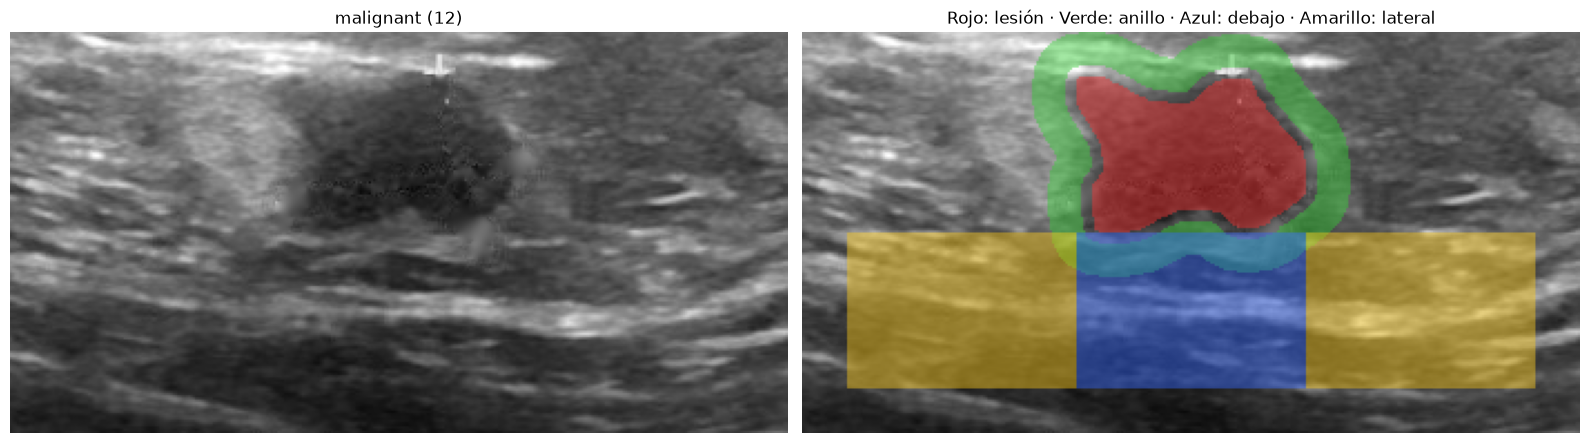

,area,alto_ancho,circularidad,solidez,excentricidad,irregularidad,media,desvio,ecogenicidad,sombra,...,homogeneidad_d4,homogeneidad_d4_rel,energia_d1,energia_d1_rel,energia_d4,energia_d4_rel,correlacion_d1,correlacion_d1_rel,correlacion_d4,correlacion_d4_rel
malignant (12),5299.0,0.68,0.604,0.846,0.771,0.225,59.054,21.419,0.479,0.838,...,0.553,1.452,0.201,1.726,0.163,1.955,0.928,-0.04,0.834,-0.017


In [8]:
EJEMPLO = "malignant (12)"
img, mascara, marcas = cargar_limpio(casos.loc[EJEMPLO])
lesion = segmentacion.lesion_principal(mascara)
anillo = dominios.anillo(lesion)
debajo, lateral = descriptores.region_sombra(lesion)
zona = dominios.recorte(lesion | debajo | lateral, margen=20)

rgb = np.dstack([img] * 3).astype(float) / 255
for region, color in [(lesion, (1, 0.2, 0.2)), (anillo, (0.2, 0.8, 0.2)), (debajo, (0.2, 0.4, 1)), (lateral, (1, 0.8, 0.1))]:
    rgb[region] = 0.55 * rgb[region] + 0.45 * np.array(color)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(img[zona], cmap="gray", vmin=0, vmax=255)
axes[0].set_title(EJEMPLO)
axes[1].imshow(rgb[zona])
axes[1].set_title("Rojo: lesión · Verde: anillo · Azul: debajo · Amarillo: lateral")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()
pd.Series(descriptores.descriptores_caso(img, lesion, excluir=marcas)).round(3).to_frame(EJEMPLO).T

**Qué vemos:** la lesión es **hipoecoica** (ecogenicidad 0,48: la mitad del brillo del tejido de alrededor) y tiene **sombra posterior** leve (0,84: debajo es un 16 % más oscuro que a los costados). Es más ancha que alta (0,68). La región "debajo" incluye parte del anillo cuando la lesión tiene el borde inferior curvo: es una aproximación, como la que hace el radiólogo a ojo.

### 3.1 Tabla de descriptores con la máscara manual

`descriptores.tabla_descriptores()` recorre las 647 imágenes. El resultado se guarda en `outputs/descriptores/`.

In [9]:
RECALCULAR = False

def calcular_tabla(mascaras=None):
    # Divide las imágenes en bloques y calcula cada bloque en un proceso distinto.
    bloques = np.array_split(np.arange(len(con_lesion)), 10)
    partes = Parallel(n_jobs=-1)(delayed(descriptores.tabla_descriptores)(
        con_lesion.iloc[b], cargar_limpio,
        None if mascaras is None else {i: mascaras[i] for i in con_lesion.index[b]}) for b in bloques)
    return pd.concat(partes)

archivo = CARPETA / "descriptores_manual.csv"
if archivo.exists() and not RECALCULAR:
    tabla_manual = pd.read_csv(archivo, index_col="id")
    print("Leído de", archivo)
else:
    tabla_manual = calcular_tabla()
    tabla_manual.to_csv(archivo)
print(f"{len(tabla_manual)} lesiones, {tabla_manual.shape[1] - 1} descriptores")
print(f"Sin sombra medible (la lesión llega al borde de abajo): {tabla_manual['sombra'].isna().sum()}")

FORMA = ["area", "alto_ancho", "circularidad", "solidez", "excentricidad", "irregularidad"]
INTENSIDAD = ["media", "desvio", "ecogenicidad", "sombra"]
TEXTURA = [c for c in tabla_manual.columns if c.endswith(("_d1", "_d4"))]
TEXTURA_REL = [c for c in tabla_manual.columns if c.endswith("_rel")]
FAMILIAS = {"forma": FORMA, "intensidad": INTENSIDAD, "textura": TEXTURA, "textura relativa": TEXTURA_REL}

Leído de /Users/luciaburman/PSIB_TPI_GRUPO_13/outputs/descriptores/descriptores_manual.csv
647 lesiones, 26 descriptores
Sin sombra medible (la lesión llega al borde de abajo): 0


## 4. ¿Qué descriptores diferencian benignas de malignas?

Para cada descriptor, la prueba U de **Mann-Whitney** (benignas vs. malignas; no supone distribución normal, como en las partes anteriores) y el **AUC del descriptor solo**: la probabilidad de que una maligna elegida al azar tenga un valor **mayor** que una benigna (0,5 = no separa; lejos de 0,5 en cualquier sentido = separa).

**Comparaciones múltiples.** Probamos 26 descriptores. Con un nivel de 0,05, si ninguno separara de verdad esperaríamos ~1,3 "significativos" por azar. La **corrección de Holm** (`descriptores.holm`) ajusta los p-valores para que la probabilidad de **algún** falso positivo en todo el conjunto sea ≤ 0,05: ordena los p-valores de menor a mayor y multiplica el primero por 26, el segundo por 25, etc. Es como Bonferroni, pero menos estricta.

Una salvedad: las imágenes casi duplicadas no son independientes. Lo comprobamos al final de la sección repitiendo el test con **una imagen por grupo**.

In [10]:
mw = descriptores.test_mann_whitney(tabla_manual)
mw["familia"] = [next(f for f, cols in FAMILIAS.items() if d in cols) for d in mw.index]
mw["auc efectivo"] = np.maximum(mw["auc"], 1 - mw["auc"])
mw["significativo (Holm)"] = np.where(mw["p_holm"] < 0.05, "sí", "no")
mw = mw.sort_values("auc efectivo", ascending=False)
mostrar = mw.copy()
mostrar["p"] = mostrar["p"].map(lambda v: f"{v:.1e}")
mostrar["p_holm"] = mostrar["p_holm"].map(lambda v: f"{v:.1e}")
mostrar.round(3)

,mediana_benignas,mediana_malignas,auc,p,p_holm,familia,auc efectivo,significativo (Holm)
descriptor,,,,,,,,
solidez,0.981,0.884,0.014,1.8e-89,4.8e-88,forma,0.986,sí
circularidad,0.775,0.559,0.144,6.9e-49,1.7e-47,forma,0.856,sí
correlacion_d4,0.771,0.894,0.814,2.0e-38,4.8e-37,textura,0.814,sí
area,10379.000,34433.000,0.766,6.5e-28,1.5e-26,forma,0.766,sí
correlacion_d1,0.959,0.977,0.765,9.6e-28,2.1e-26,textura,0.765,sí
sombra,1.217,0.842,0.258,1.9e-23,3.9e-22,intensidad,0.742,sí
contraste_d4,5.715,3.485,0.296,4.9e-17,9.7e-16,textura,0.704,sí
alto_ancho,0.594,0.720,0.700,1.5e-16,2.8e-15,forma,0.700,sí
contraste_d1,1.160,0.811,0.319,7.4e-14,1.3e-12,textura,0.681,sí


**Qué vemos:** **22 de los 26 descriptores** difieren significativamente entre clases después de la corrección de Holm. Ordenados por AUC efectivo:
- **Forma:** la **solidez** (AUC efectivo 0,99: malignas 0,88 contra benignas 0,98) y la **circularidad** (0,86) separan muchísimo; el **área** (0,77: las malignas son ~3 veces más grandes en mediana) y el **alto/ancho** (0,70: malignas 0,72 contra 0,59) también. La **irregularidad** (desvío radial) **no** separa (p Holm = 1).
- **Intensidad:** la **sombra posterior** es el mejor descriptor de intensidad (0,74): debajo de las malignas hay **sombra** (0,84) y debajo de las benignas **refuerzo** (1,22), exactamente lo que describe BI-RADS (los quistes y fibroadenomas dejan pasar el sonido). La **ecogenicidad relativa** separa poco (0,62) y al revés de lo que podría esperarse: las malignas son **menos** hipoecoicas respecto de su anillo (0,59 contra 0,52), porque su tejido de alrededor es más oscuro (lo mismo que vimos en la Parte 0). La **media** sola no separa.
- **Textura:** la **correlación** de la GLCM (0,81 a distancia 4) y el **contraste** (0,70): la textura de las malignas tiene **menos contraste y más correlación** entre vecinos, o sea, es **más lisa**, no más heterogénea.
- **Textura relativa:** la homogeneidad y la energía relativas separan moderadamente (0,58–0,64); el contraste relativo no separa.

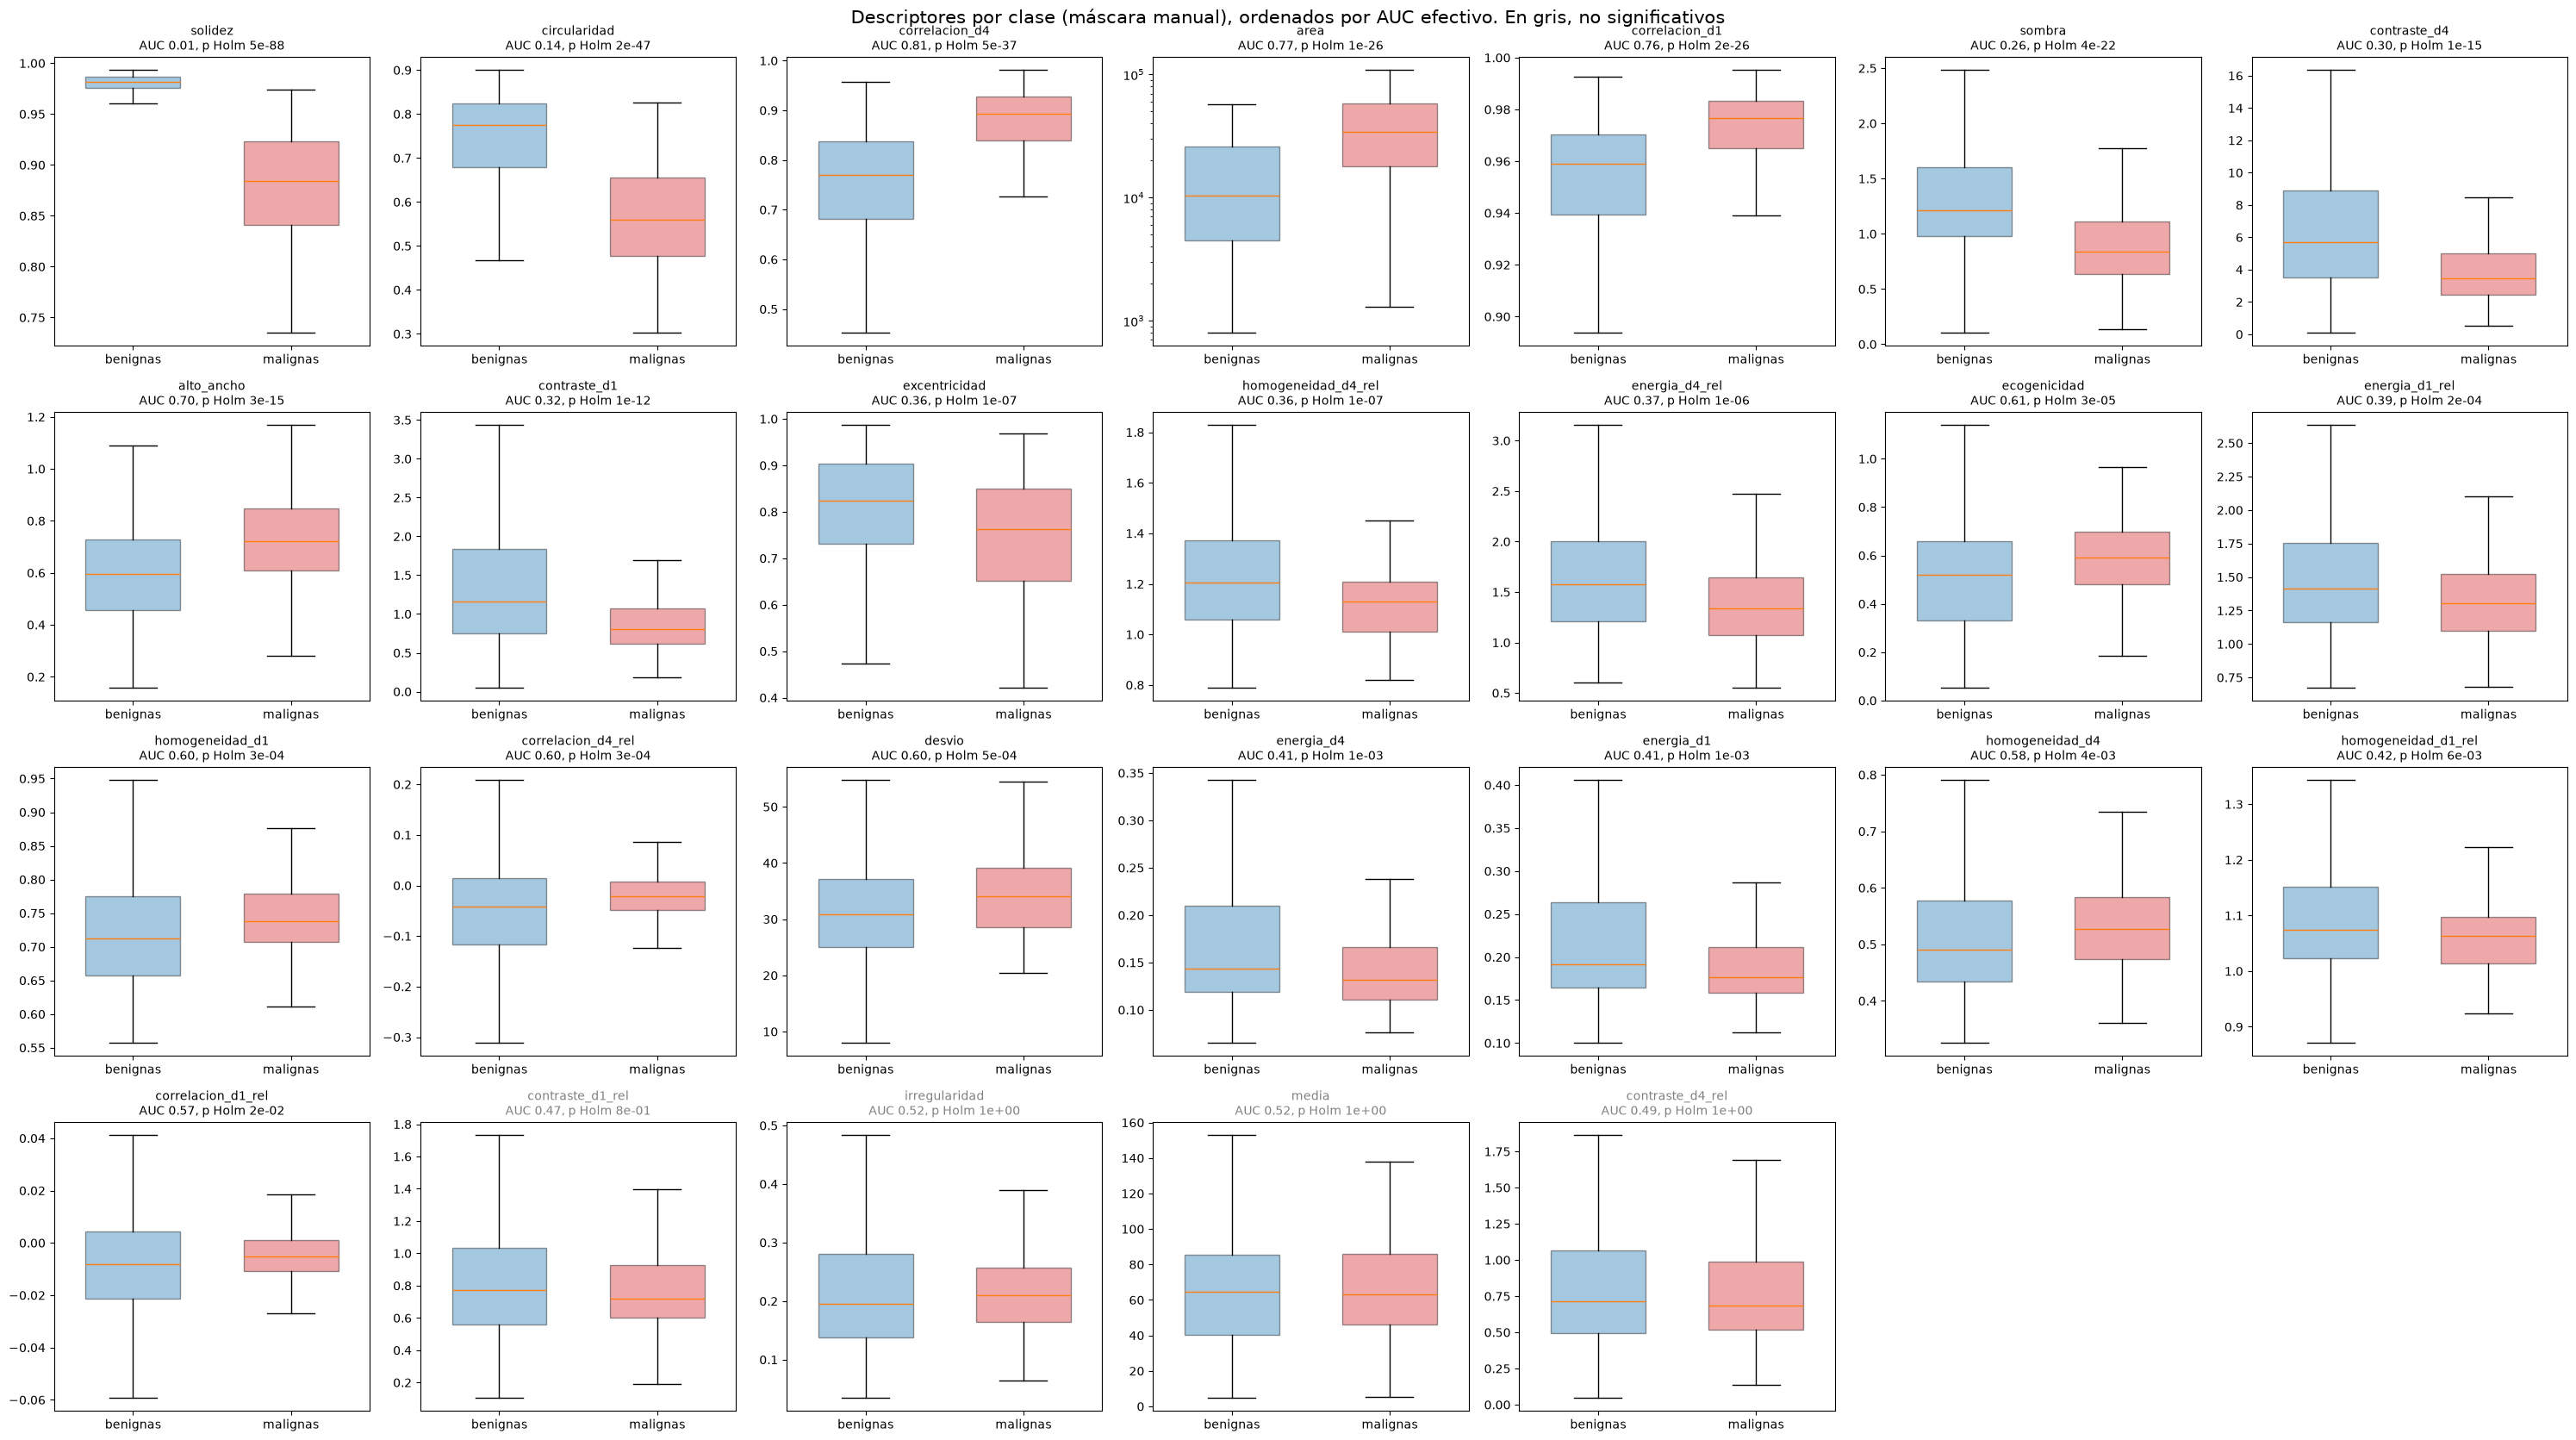

In [11]:
fig, axes = plt.subplots(4, 7, figsize=(30, 17))
for ax, d in zip(axes.flat, mw.index):
    datos = [tabla_manual.loc[tabla_manual["clase"] == c, d].dropna() for c in ("benign", "malignant")]
    caja = ax.boxplot(datos, tick_labels=["benignas", "malignas"], showfliers=False, patch_artist=True, widths=0.6)
    for parche, color in zip(caja["boxes"], ["tab:blue", "tab:red"]):
        parche.set_facecolor(color)
        parche.set_alpha(0.4)
    if d == "area":
        ax.set_yscale("log")
    ax.set_title(f"{d}\nAUC {mw.loc[d, 'auc']:.2f}, p Holm {mw.loc[d, 'p_holm']:.0e}", fontsize=10,
                 color="black" if mw.loc[d, "p_holm"] < 0.05 else "gray")
for ax in axes.flat[len(mw):]:
    ax.axis("off")
fig.suptitle("Descriptores por clase (máscara manual), ordenados por AUC efectivo. En gris, no significativos", fontsize=15)
plt.tight_layout()
plt.show()

**Qué vemos:** las cajas de la solidez y la circularidad casi no se superponen; en el resto la superposición es grande, aunque las medianas difieran. Que un descriptor sea **significativo** (p chico) no quiere decir que **clasifique** bien: con 647 imágenes, una diferencia chica entre medianas ya es significativa. Por eso miramos el AUC.

### 4.1 ¿La forma es de la lesión o del dibujo?

La forma separa las clases **demasiado bien**: la solidez sola tiene AUC 0,99 (en la sección 4 aparece como 0,014 porque las malignas tienen **menos** solidez). Ningún rasgo BI-RADS es tan determinante en la práctica clínica, así que vale la pena mirar **cómo están dibujadas** las máscaras. Comparamos el contorno manual (verde) con nuestra segmentación (naranja) en lesiones al azar de cada clase:

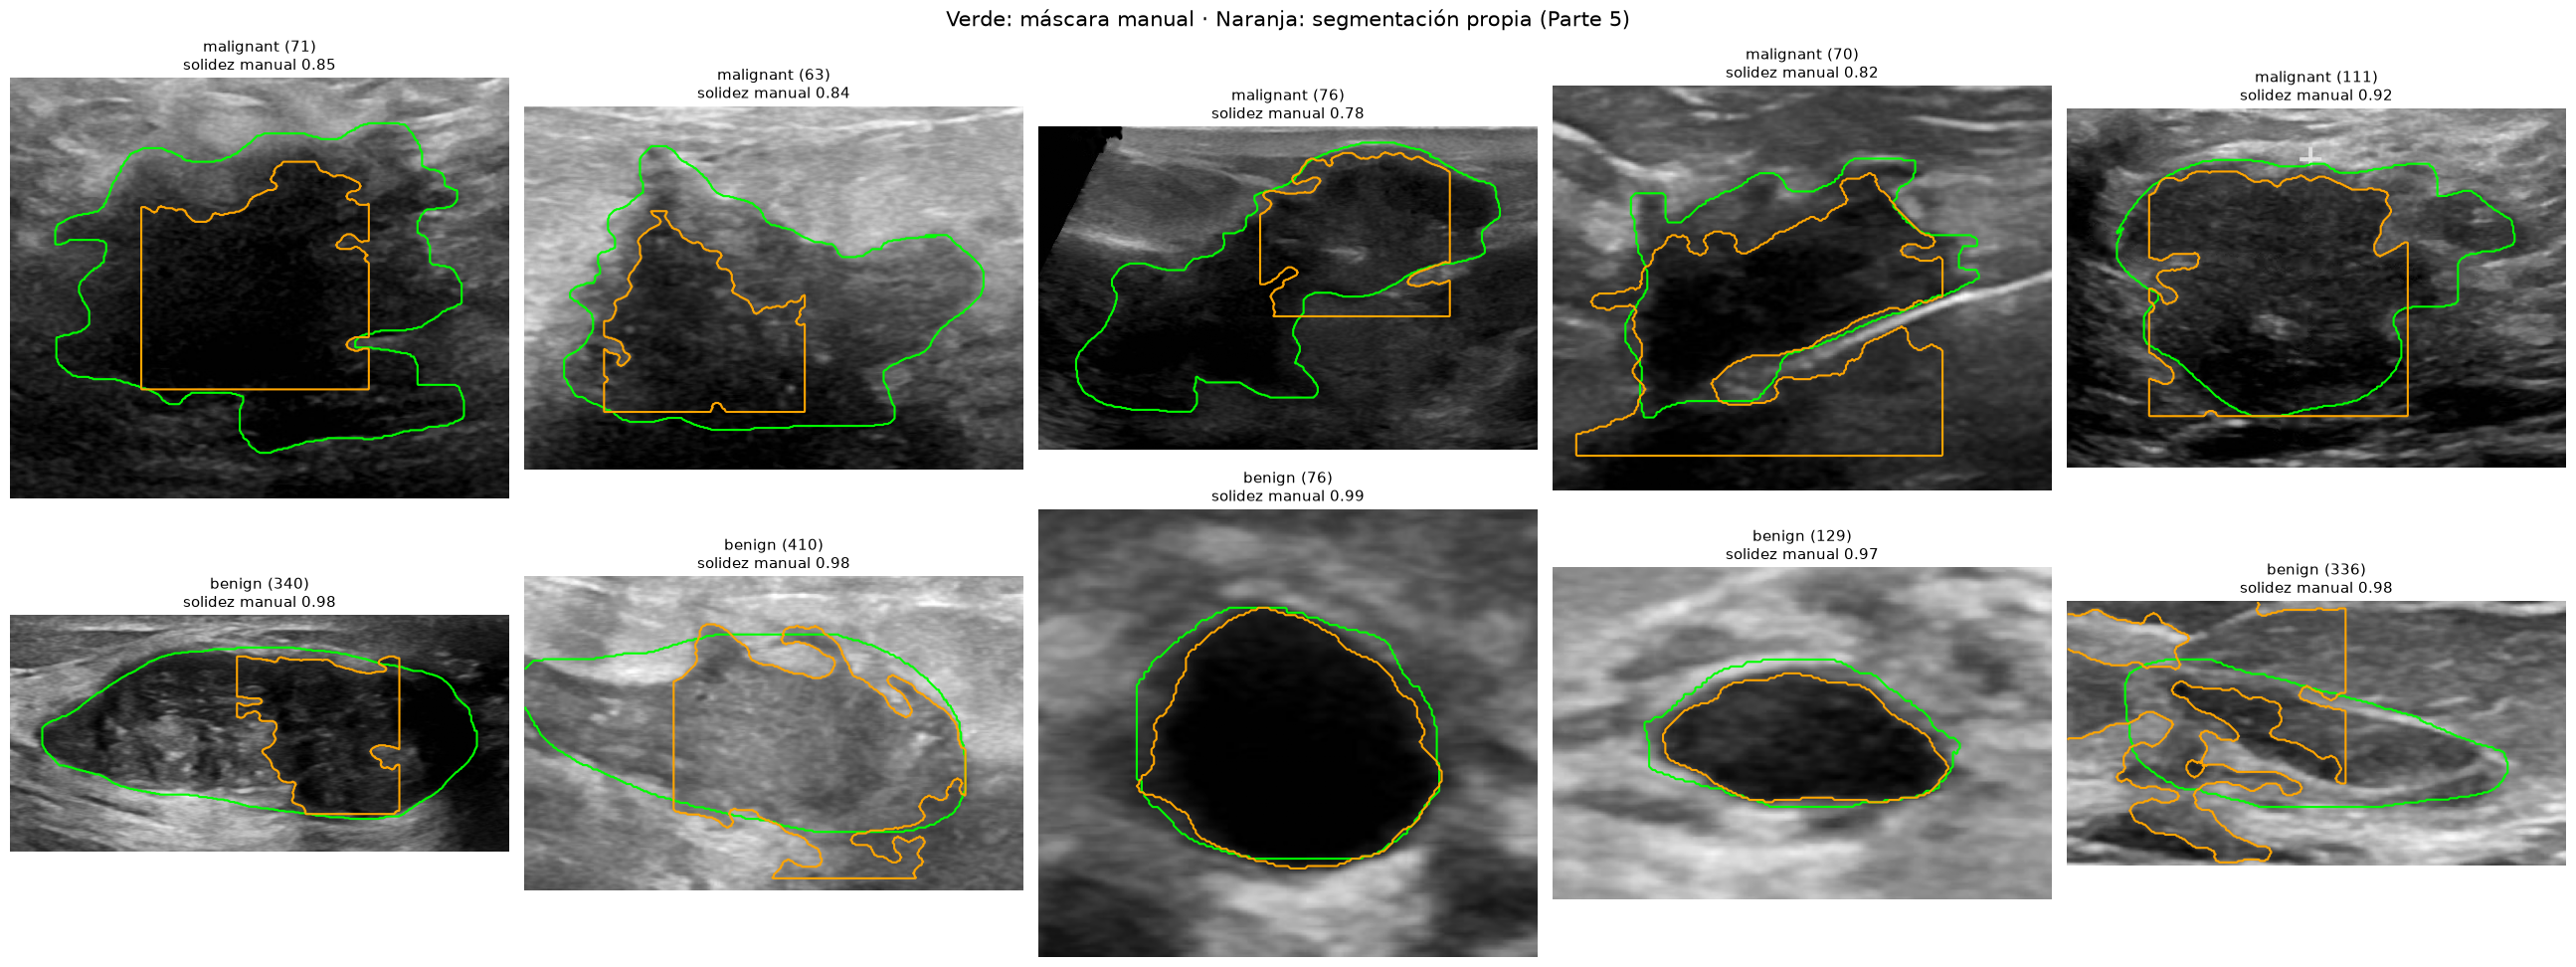

In [12]:
seg_mejor = np.load(cfg["OUTPUT_DIR"] / "segmentacion" / "mascaras_rg_imagen.npz")
rng = np.random.default_rng(SEED)
muestra = {c: rng.choice(tabla_manual.index[tabla_manual["clase"] == c], 5, replace=False) for c in ("malignant", "benign")}
fig, axes = plt.subplots(2, 5, figsize=(26, 10))
for fila, (c, ids_c) in zip(axes, muestra.items()):
    for ax, id_caso in zip(fila, ids_c):
        img, mascara, _ = cargar_limpio(casos.loc[id_caso])
        lesion = segmentacion.lesion_principal(mascara)
        z = dominios.recorte(lesion, margen=40)
        ax.imshow(img[z], cmap="gray", vmin=0, vmax=255)
        ax.contour(lesion[z], levels=[0.5], colors="lime", linewidths=1.5)
        if seg_mejor[id_caso].any():
            ax.contour(seg_mejor[id_caso][z], levels=[0.5], colors="orange", linewidths=1.5)
        ax.set_title(f"{id_caso}\nsolidez manual {tabla_manual.loc[id_caso, 'solidez']:.2f}", fontsize=11)
        ax.axis("off")
fig.suptitle("Verde: máscara manual · Naranja: segmentación propia (Parte 5)", fontsize=15)
plt.tight_layout()
plt.show()

Para cuantificarlo, comparamos cada máscara manual con **su elipse equivalente**: la elipse con el mismo centro, la misma orientación y el mismo "estiramiento" que la máscara (los momentos de segundo orden: los píxeles cuya distancia de Mahalanobis al centro es ≤ 2). El IoU entre la máscara y su elipse mide **qué tan "de elipse" está dibujada**: 1 = es una elipse perfecta.

In [13]:
def iou_elipse(mascara):
    # IoU entre la máscara y la elipse con sus mismos momentos de segundo orden.
    ys, xs = np.nonzero(mascara)
    centro = np.array([ys.mean(), xs.mean()])
    inversa = np.linalg.inv(np.cov(np.c_[ys, xs].T))
    yy, xx = np.indices(mascara.shape)
    d = np.stack([yy - centro[0], xx - centro[1]], axis=-1)
    elipse = np.einsum("...i,ij,...j->...", d, inversa, d) <= 4     # para una elipse uniforme, el borde está en d² = 4
    return segmentacion.iou(mascara, elipse)

elipse_iou = pd.Series({i: iou_elipse(segmentacion.lesion_principal(cargar_caso(casos.loc[i])[1]))
                        for i in tabla_manual.index})
print(elipse_iou.groupby(tabla_manual["clase"]).describe(percentiles=[0.1, 0.5, 0.9]).round(3))
for c in ("benign", "malignant"):
    print(f"{c}: {100 * (elipse_iou[tabla_manual['clase'] == c] > 0.95).mean():.0f} % de las máscaras con IoU > 0,95 con su elipse")
print(f"AUC del IoU con la elipse como descriptor: {roc_auc_score(tabla_manual['clase'] == 'malignant', elipse_iou):.3f}")

           count   mean    std    min    10%    50%    90%    max
clase                                                            
benign     437.0  0.920  0.035  0.692  0.875  0.927  0.955  0.974
malignant  210.0  0.811  0.065  0.597  0.729  0.820  0.890  0.933
benign: 15 % de las máscaras con IoU > 0,95 con su elipse
malignant: 0 % de las máscaras con IoU > 0,95 con su elipse
AUC del IoU con la elipse como descriptor: 0.056


**Qué vemos:** las máscaras de las **benignas** están dibujadas como **elipses casi perfectas**: su IoU mediano con la elipse equivalente es 0,93, y el 15 % supera 0,95. Las de las **malignas**, a mano alzada con lóbulos y ángulos: IoU mediano 0,82, ninguna por encima de 0,95. **Esa sola medida ("qué tan de elipse está dibujada la máscara") separa las clases con AUC 0,94.** En las imágenes se ve: las máscaras benignas son contornos suaves y convexos aun cuando el borde de la lesión no es tan regular (`benign (410)`, `benign (336)`), y las malignas siguen cada lóbulo y entrante (`malignant (71)`, `malignant (63)`). Nuestra segmentación (naranja) no reproduce esos detalles en ninguna de las dos clases: sus irregularidades vienen de fugas y de los cortes rectos de la ventana.

¿Es la forma de la lesión o el estilo del dibujo? Las dos cosas, y con estos datos **no se pueden separar**:
- BI-RADS dice que las benignas suelen ser ovaladas y circunscriptas y las malignas irregulares, así que parte de la diferencia es real;
- pero quien dibujó las máscaras **conocía el diagnóstico** (BUSI se armó con lesiones ya diagnosticadas), y la diferencia en el **estilo** (elipses suaves contra contornos detallados) es demasiado sistemática para ser solo anatomía.

**Consecuencia:** los descriptores de forma calculados sobre la **máscara manual** no estiman lo que un sistema automático podría lograr. La comparación con nuestra segmentación (sección 6) es la medida honesta.

### 4.2 ¿La textura de la lesión o la de la imagen?

La Parte 2 mostró que el tejido de las malignas tiene μ/σ más alto **lejos** de la lesión. Si la textura de la lesión separa las clases solo porque "toda la imagen" de las malignas es distinta, el mismo descriptor medido en el **anillo de tejido** también debería separarlas. Lo verificamos para la GLCM del anillo, y comparamos con la versión relativa:

In [14]:
def glcm_anillo(caso):
    img, mascara, marcas = cargar_limpio(caso)
    lesion = segmentacion.lesion_principal(mascara)
    return dominios.glcm_region(img.astype(float), dominios.anillo(lesion) & ~marcas, 32, (1, 4),
                                descriptores.PROPIEDADES_GLCM)

archivo_anillo = CARPETA / "glcm_anillo.csv"
if archivo_anillo.exists() and not RECALCULAR:
    anillo_tabla = pd.read_csv(archivo_anillo, index_col="id")
else:
    anillo_tabla = pd.DataFrame(Parallel(n_jobs=-1)(delayed(glcm_anillo)(c) for _, c in con_lesion.iterrows()),
                                index=con_lesion.index)
    anillo_tabla.index.name = "id"
    anillo_tabla.to_csv(archivo_anillo)
anillo_tabla = anillo_tabla.rename(columns=lambda c: descriptores.NOMBRES_GLCM[c.rsplit("_", 1)[0]] + "_" + c.rsplit("_", 1)[1])
anillo_tabla["clase"] = con_lesion["clase"]
mw_anillo = descriptores.test_mann_whitney(anillo_tabla)

comparacion = pd.DataFrame({
    "AUC lesión": mw.loc[TEXTURA, "auc"],
    "AUC anillo (tejido)": mw_anillo.loc[TEXTURA, "auc"],
    "p Holm anillo": mw_anillo.loc[TEXTURA, "p_holm"].map(lambda v: f"{v:.1e}"),
    "AUC lesión / anillo": mw.loc[[t + "_rel" for t in TEXTURA], "auc"].to_numpy(),
})
comparacion.round(3)

,AUC lesión,AUC anillo (tejido),p Holm anillo,AUC lesión / anillo
descriptor,,,,
contraste_d1,0.319,0.297,1.7e-16,0.469
contraste_d4,0.296,0.244,3.9e-25,0.493
homogeneidad_d1,0.603,0.714,4.7e-18,0.420
homogeneidad_d4,0.584,0.771,3.8e-28,0.360
energia_d1,0.407,0.569,4.7e-03,0.395
energia_d4,0.407,0.620,1.4e-06,0.370
correlacion_d1,0.765,0.718,1.1e-18,0.571
correlacion_d4,0.814,0.753,1.0e-24,0.603


**Qué vemos:** **la textura del tejido de alrededor separa las clases tanto o más que la textura de la lesión.** En el anillo, el contraste tiene AUC 0,24–0,30 (en la lesión, 0,30–0,32), la homogeneidad 0,71–0,77 (en la lesión, 0,58–0,60) y la correlación 0,72–0,75 (en la lesión, 0,77–0,81). Es lo que había anticipado la Parte 2: el tejido de las imágenes malignas es más "liso" (μ/σ más alto) **aunque esté lejos de la lesión**.

Hay dos explicaciones posibles, que no podemos separar: la **adquisición** (otra configuración del equipo para las malignas) o el **tejido vecino** (el anillo de 5 a 20 px incluye el halo y la reacción del tejido alrededor de los tumores malignos, que BI-RADS describe como rasgo sospechoso).

**Los descriptores relativos** (lesión / anillo) sacan lo que comparten la lesión y su entorno. El contraste relativo deja de separar (0,47–0,49): **la diferencia de contraste no era propia de la lesión**. En cambio, la homogeneidad y la energía relativas siguen separando (0,36–0,42): en las benignas la lesión es bastante más homogénea que su entorno (homogeneidad relativa 1,21 en mediana), en las malignas algo menos (1,13). Ese sí es un rasgo propio de la lesión, y va en el sentido de la hipótesis: **relativa a su entorno, la textura de las malignas es más heterogénea**.

### 4.3 Control: una imagen por grupo de duplicados

Repetimos el test quedándonos con **una sola imagen de cada grupo** (la primera), para ver si las casi-duplicadas inflaban la significación.

In [15]:
grupo_tabla = grupos.loc[tabla_manual.index]
una_por_grupo = tabla_manual[~grupo_tabla.duplicated()]
mw_unica = descriptores.test_mann_whitney(una_por_grupo)
control = pd.DataFrame({"AUC todas": mw["auc"], "p Holm todas": mw["p_holm"],
                        "AUC una por grupo": mw_unica["auc"], "p Holm una por grupo": mw_unica["p_holm"]}).loc[mw.index]
print(f"{len(una_por_grupo)} imágenes (de {len(tabla_manual)})")
print(f"Significativos (Holm < 0,05): todas {(control['p Holm todas'] < 0.05).sum()}, "
      f"una por grupo {(control['p Holm una por grupo'] < 0.05).sum()}")
control.assign(**{c: control[c].map(lambda v: f'{v:.1e}') for c in ["p Holm todas", "p Holm una por grupo"]}).round(3)

498 imágenes (de 647)
Significativos (Holm < 0,05): todas 22, una por grupo 20


,AUC todas,p Holm todas,AUC una por grupo,p Holm una por grupo
descriptor,,,,
solidez,0.014,4.8e-88,0.013,4.5e-72
circularidad,0.144,1.7e-47,0.143,6.0e-39
correlacion_d4,0.814,4.8e-37,0.807,7.2e-29
area,0.766,1.5e-26,0.763,2.7e-21
correlacion_d1,0.765,2.1e-26,0.752,1.5e-19
sombra,0.258,3.9e-22,0.248,1.3e-19
contraste_d4,0.296,9.7e-16,0.308,1.9e-11
alto_ancho,0.700,2.8e-15,0.689,4.1e-11
contraste_d1,0.319,1.3e-12,0.337,2.2e-08


**Qué vemos:** con una imagen por grupo (498 escenas), los AUC prácticamente no cambian (diferencias de ±0,02) y siguen siendo significativos 20 de los 22 descriptores; solo dejan de serlo la homogeneidad a distancia 4 (p Holm = 0,08) y la correlación relativa a distancia 1 (p = 0,13), que ya estaban cerca del límite. **Los duplicados no explican las diferencias entre clases.**

## 5. Clasificador: regresión logística

Combinamos los descriptores en un clasificador simple, como propone el anteproyecto: **regresión logística**, que estima la probabilidad de que la lesión sea maligna como $p = 1 / (1 + e^{-(w_0 + w_1 x_1 + \dots)})$. Es interpretable: cada peso $w_i$ dice cuánto empuja cada descriptor (estandarizado) hacia "maligna".

Decisiones (`descriptores.evaluar_clasificador`):
- **Desbalance** (437 benignas, 210 malignas): `class_weight="balanced"` pesa más los errores en la clase minoritaria. Sin esto, el modelo puede tener buena exactitud diciendo casi siempre "benigna".
- **Validación cruzada agrupada y estratificada** (`StratifiedGroupKFold`, 5 pliegues): se entrena con 4/5 de las imágenes y se prueba con el 1/5 restante, rotando. Cada pliegue tiene una proporción de malignas parecida a la total (**estratificada**), y todas las imágenes de un **grupo de duplicados** caen en el mismo pliegue (**agrupada**), así nunca están en entrenamiento y prueba a la vez.
- Faltantes (la sombra de las lesiones que tocan el borde de abajo): se completan con la mediana del entrenamiento. Estandarización también con el entrenamiento.
- Medidas: **sensibilidad** (fracción de malignas detectadas), **especificidad** (fracción de benignas bien clasificadas), con el umbral 0,5, y **AUC** (no depende del umbral: probabilidad de que el modelo le dé más probabilidad a una maligna que a una benigna, elegidas al azar).

Probamos cada familia por separado y todas juntas.

In [16]:
y = (tabla_manual["clase"] == "malignant").astype(int).to_numpy()
g = grupos.loc[tabla_manual.index].to_numpy()
CONJUNTOS = dict(FAMILIAS, **{"textura (abs. + relativa)": TEXTURA + TEXTURA_REL, "todos": FORMA + INTENSIDAD + TEXTURA + TEXTURA_REL})

def resumir(por_pliegue, prob, y):
    return {"sensibilidad": f"{por_pliegue['sensibilidad'].mean():.2f} ± {por_pliegue['sensibilidad'].std():.2f}",
            "especificidad": f"{por_pliegue['especificidad'].mean():.2f} ± {por_pliegue['especificidad'].std():.2f}",
            "AUC (media de pliegues)": f"{por_pliegue['auc'].mean():.3f} ± {por_pliegue['auc'].std():.3f}",
            "AUC (todas las predicciones)": roc_auc_score(y, prob)}

resultados, probabilidades = {}, {}
for nombre, cols in CONJUNTOS.items():
    por_pliegue, prob = descriptores.evaluar_clasificador(tabla_manual[cols], y, g, seed=SEED)
    resultados[nombre] = resumir(por_pliegue, prob, y)
    probabilidades[nombre] = prob
pd.DataFrame(resultados).T.round(3)

,sensibilidad,especificidad,AUC (media de pliegues),AUC (todas las predicciones)
forma,0.95 ± 0.03,0.97 ± 0.02,0.993 ± 0.006,0.992503
intensidad,0.71 ± 0.07,0.70 ± 0.08,0.751 ± 0.033,0.753231
textura,0.83 ± 0.07,0.73 ± 0.04,0.837 ± 0.021,0.839337
textura relativa,0.84 ± 0.04,0.63 ± 0.07,0.790 ± 0.049,0.789637
textura (abs. + relativa),0.88 ± 0.05,0.74 ± 0.06,0.866 ± 0.042,0.864727
todos,0.95 ± 0.02,0.98 ± 0.02,0.988 ± 0.009,0.987044


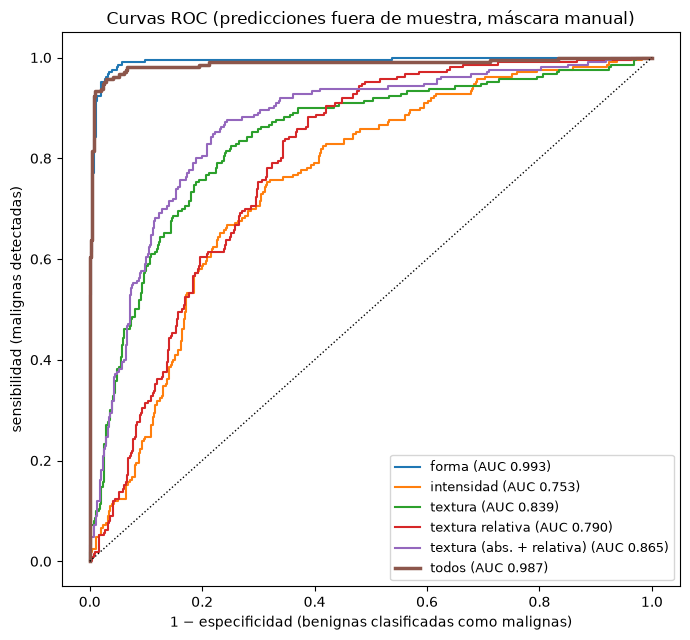

In [17]:
fig, ax = plt.subplots(figsize=(7, 6.5))
for nombre, prob in probabilidades.items():
    fpr, tpr, _ = roc_curve(y, prob)
    ax.plot(fpr, tpr, label=f"{nombre} (AUC {roc_auc_score(y, prob):.3f})", linewidth=2.5 if nombre == "todos" else 1.5)
ax.plot([0, 1], [0, 1], "k:", linewidth=1)
ax.set_xlabel("1 − especificidad (benignas clasificadas como malignas)")
ax.set_ylabel("sensibilidad (malignas detectadas)")
ax.set_title("Curvas ROC (predicciones fuera de muestra, máscara manual)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Qué vemos:**
- **Con la forma sola, el clasificador es casi perfecto:** AUC 0,993, sensibilidad 0,95 y especificidad 0,97. Por lo visto en la sección 4.1, este número **mide en gran parte el estilo de las máscaras**, no lo que se podría lograr sin ellas.
- La **intensidad** sola llega a AUC 0,75 (sobre todo por la sombra posterior). La **textura** absoluta, a 0,84, y la **relativa**, a 0,79; juntas, **0,865** (sensibilidad 0,88, especificidad 0,74). La textura relativa pierde algo respecto de la absoluta, porque le saca lo que el tejido comparte con la lesión, que también separa las clases (sección 4.2), aunque no sea propio de la lesión.
- **Todos juntos** dan AUC 0,988, apenas por debajo de la forma sola: con 26 descriptores y 647 imágenes, agregar descriptores que separan menos no mejora.
- Los desvíos entre pliegues son chicos (± 0,01 a ± 0,05): el resultado no depende de cómo cayó la partición.

### 5.1 ¿Qué pesa en el modelo?

Pesos de la regresión logística con **todos** los descriptores, ajustada en cada pliegue (los descriptores están estandarizados, así que los pesos son comparables entre sí). Positivo = empuja hacia maligna. Mostramos la media y el rango de los 5 pliegues: si un peso cambia de signo entre pliegues, no es confiable.

In [18]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

cols = CONJUNTOS["todos"]
pesos = []
for entrena, _ in StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(tabla_manual[cols], y, g):
    modelo = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                           LogisticRegression(class_weight="balanced", max_iter=2000))
    modelo.fit(tabla_manual[cols].iloc[entrena], y[entrena])
    pesos.append(modelo[-1].coef_[0])
pesos = pd.DataFrame(pesos, columns=cols)
resumen_pesos = pd.DataFrame({"peso medio": pesos.mean(), "mínimo": pesos.min(), "máximo": pesos.max()})
resumen_pesos["mismo signo en los 5 pliegues"] = np.where(np.sign(pesos.min()) == np.sign(pesos.max()), "sí", "no")
resumen_pesos.reindex(resumen_pesos["peso medio"].abs().sort_values(ascending=False).index).round(2)

,peso medio,mínimo,máximo,mismo signo en los 5 pliegues
solidez,-4.19,-4.60,-3.93,sí
irregularidad,-2.00,-2.19,-1.77,sí
circularidad,-1.82,-2.06,-1.47,sí
contraste_d4,-0.87,-1.00,-0.73,sí
energia_d4_rel,-0.60,-0.78,-0.29,sí
homogeneidad_d4_rel,-0.55,-0.81,-0.23,sí
correlacion_d4,0.54,0.38,0.88,sí
contraste_d1,0.54,0.02,0.76,sí
alto_ancho,0.53,0.24,0.91,sí
energia_d1_rel,-0.48,-0.65,-0.16,sí


**Qué vemos:**
- La **solidez** domina el modelo (peso −4,2: menos solidez → maligna), seguida por la **irregularidad** (−2,0) y la **circularidad** (−1,8), todas con el mismo signo en los 5 pliegues.
- La **irregularidad** tiene peso **negativo** aunque sola no separaba las clases. Es un efecto de la **colinealidad**: el modelo la usa para corregir la solidez y la circularidad, con las que está correlacionada. Una lectura posible: a igual solidez, un desvío radial alto indica una lesión alargada pero suave (benigna) más que una lobulada. Por eso los pesos de descriptores correlacionados **no se pueden leer uno por uno**.
- 17 de los 26 pesos tienen el mismo signo en los 5 pliegues. Los otros 9 (cuatro de textura absoluta, tres de textura relativa, el desvío y la ecogenicidad) cambian de signo: el modelo no los usa de forma estable.

### 5.2 ¿Cuánto inflan los duplicados?

La misma validación cruzada **sin agrupar** (`StratifiedKFold`): las casi-duplicadas pueden caer en entrenamiento y prueba a la vez. Repetimos las dos con 10 semillas distintas de partición para no depender de una sola.

In [19]:
def auc_cv(X, agrupar, semilla):
    X = np.asarray(X, float)
    if agrupar:
        return descriptores.evaluar_clasificador(X, y, g, seed=semilla)[0]["auc"].mean()
    aucs = []
    for entrena, prueba in StratifiedKFold(5, shuffle=True, random_state=semilla).split(X, y):
        modelo = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                               LogisticRegression(class_weight="balanced", max_iter=2000))
        modelo.fit(X[entrena], y[entrena])
        aucs.append(roc_auc_score(y[prueba], modelo.predict_proba(X[prueba])[:, 1]))
    return np.mean(aucs)

filas = []
for nombre in ["forma", "textura (abs. + relativa)", "todos"]:
    X = tabla_manual[CONJUNTOS[nombre]]
    agrupada = [auc_cv(X, True, s) for s in range(10)]
    sin_agrupar = [auc_cv(X, False, s) for s in range(10)]
    filas.append({"descriptores": nombre, "AUC agrupada": np.mean(agrupada), "AUC sin agrupar": np.mean(sin_agrupar),
                  "diferencia": np.mean(sin_agrupar) - np.mean(agrupada)})
pd.DataFrame(filas).set_index("descriptores").round(3)

,AUC agrupada,AUC sin agrupar,diferencia
descriptores,,,
forma,0.993,0.994,0.000
textura (abs. + relativa),0.865,0.871,0.006
todos,0.988,0.990,0.001


**Qué vemos:** sin agrupar, el AUC sube **muy poco** (de 0,000 a 0,006). Los duplicados, en este caso, **casi no inflan** el resultado. Tiene sentido: con descriptores que resumen la lesión en pocos números (y no la imagen píxel a píxel, como una red neuronal), dos tomas parecidas no le dan al modelo un "atajo" muy distinto de lo que ya aprendió de otras lesiones. Igual era necesario controlarlo: con un clasificador que mira la imagen completa, la fuga podría ser grande.

## 6. Máscara manual vs. segmentación propia

Hasta acá usamos la máscara del radiólogo, para medir la capacidad de los **descriptores** sin errores de segmentación. En un sistema real no hay máscara: hay que usar nuestra segmentación. Repetimos todo con las máscaras del **mejor método de la Parte 5**.

In [20]:
seg = pd.read_csv(cfg["OUTPUT_DIR"] / "segmentacion" / "evaluacion.csv")
METODO = seg.groupby("metodo")["dice"].mean().idxmax()
dice_seg = seg[seg["metodo"] == METODO].set_index("id")["dice"]
print(f"Mejor método de la Parte 5: {METODO} (Dice medio en las 647: {dice_seg.mean():.3f})")

archivo_seg = CARPETA / f"descriptores_{METODO}.csv"
if archivo_seg.exists() and not RECALCULAR:
    tabla_seg = pd.read_csv(archivo_seg, index_col="id")
else:
    mascaras_seg = np.load(cfg["OUTPUT_DIR"] / "segmentacion" / f"mascaras_{METODO}.npz")
    tabla_seg = calcular_tabla({i: mascaras_seg[i] for i in con_lesion.index})
    tabla_seg.to_csv(archivo_seg)
print(f"{len(tabla_seg)} lesiones con segmentación no vacía (de {len(con_lesion)})")

Mejor método de la Parte 5: rg_imagen (Dice medio en las 647: 0.658)
645 lesiones con segmentación no vacía (de 647)


### 6.1 ¿Cuánto se parecen los descriptores?

Para cada descriptor, la **correlación de Spearman** entre el valor con la máscara manual y con la segmentación (1 = ordenan las lesiones igual) y el AUC benigna/maligna con cada una.

In [21]:
comunes = tabla_seg.index.intersection(tabla_manual.index)
mw_seg = descriptores.test_mann_whitney(tabla_seg)
acuerdo = pd.DataFrame({
    "Spearman manual vs. seg.": [spearmanr(tabla_manual.loc[comunes, d], tabla_seg.loc[comunes, d], nan_policy="omit").statistic
                                 for d in mw.index],
    "AUC manual": mw["auc"], "AUC segmentación": mw_seg.loc[mw.index, "auc"],
    "p Holm segmentación": mw_seg.loc[mw.index, "p_holm"].map(lambda v: f"{v:.1e}"),
}, index=mw.index)
print(f"Significativos (Holm): manual {(mw['p_holm'] < 0.05).sum()}, segmentación {(mw_seg['p_holm'] < 0.05).sum()}")
acuerdo.round(3)

Significativos (Holm): manual 22, segmentación 17


,Spearman manual vs. seg.,AUC manual,AUC segmentación,p Holm segmentación
descriptor,,,,
solidez,0.101,0.014,0.453,2.2e-01
circularidad,0.286,0.144,0.435,6.1e-02
correlacion_d4,0.659,0.814,0.704,9.9e-16
area,0.801,0.766,0.706,4.8e-16
correlacion_d1,0.517,0.765,0.707,2.9e-16
sombra,0.859,0.258,0.266,1.4e-20
contraste_d4,0.619,0.296,0.440,8.5e-02
alto_ancho,0.362,0.700,0.733,1.6e-20
contraste_d1,0.779,0.319,0.415,4.4e-03


**Qué vemos:**
- **Los descriptores de intensidad y de textura se conservan bien** con nuestra segmentación: la media (Spearman 0,91), la homogeneidad (0,86–0,88), la sombra (0,86), la ecogenicidad (0,85) y el área (0,80). Sus AUC casi no cambian (sombra 0,27 en las dos; ecogenicidad 0,62 en las dos).
- **Los descriptores de forma que dependen del detalle del contorno se pierden:** la solidez (Spearman 0,10) y la circularidad (0,29) **dejan de separar las clases** (AUC 0,45 y 0,44, no significativos). Nuestra segmentación tiene entrantes por otras razones (fugas, cortes de la ventana) que no tienen que ver con la clase.
- En cambio, el **alto/ancho** (AUC 0,73 contra 0,70) y la **excentricidad** (0,72 contra 0,64) separan **igual o mejor** con nuestra segmentación: miden la forma "gruesa" de la lesión (orientación, alargamiento), que la segmentación sí captura.
- Algunos descriptores de textura relativa (el contraste relativo, la correlación relativa) se vuelven significativos **solo** con la segmentación. Probablemente reflejan errores de segmentación que dependen de la clase (las malignas se segmentan peor, Parte 5): no los interpretamos como rasgos de la lesión.

### 6.2 El clasificador con la segmentación

Mismo procedimiento (misma validación agrupada) con los descriptores de la segmentación. Para que la comparación sea justa, usamos en los dos casos **las mismas imágenes** (las que tienen segmentación no vacía). Y separamos las imágenes según qué tan buena fue la segmentación.

In [22]:
y_c = (tabla_manual.loc[comunes, "clase"] == "malignant").astype(int).to_numpy()
g_c = grupos.loc[comunes].to_numpy()
filas, prob_c = [], {}
for nombre in ["forma", "intensidad", "textura (abs. + relativa)", "todos"]:
    cols = CONJUNTOS[nombre]
    for fuente, t in [("manual", tabla_manual), ("segmentación", tabla_seg)]:
        por_pliegue, prob = descriptores.evaluar_clasificador(t.loc[comunes, cols], y_c, g_c, seed=SEED)
        prob_c[(nombre, fuente)] = prob
        filas.append(dict(descriptores=nombre, máscara=fuente, **resumir(por_pliegue, prob, y_c)))
pd.DataFrame(filas).set_index(["descriptores", "máscara"]).round(3)

sensibilidad especificidad  \
descriptores              máscara                                   
forma                     manual        0.95 ± 0.02   0.98 ± 0.02   
                          segmentación  0.75 ± 0.03   0.64 ± 0.08   
intensidad                manual        0.72 ± 0.06   0.70 ± 0.12   
                          segmentación  0.69 ± 0.06   0.71 ± 0.09   
textura (abs. + relativa) manual        0.88 ± 0.08   0.74 ± 0.04   
                          segmentación  0.80 ± 0.11   0.71 ± 0.04   
todos                     manual        0.95 ± 0.02   0.98 ± 0.03   
                          segmentación  0.82 ± 0.09   0.76 ± 0.05   

                                       AUC (media de pliegues)  \
descriptores              máscara                                
forma                     manual                 0.993 ± 0.006   
                          segmentación           0.747 ± 0.047   
intensidad                manual                 0.760 ± 0.079   
                          segmentación           0.780 ± 0.050   
textura (abs. + relativa) manual                 0.869 ± 0.038   
                          segmentación           0.820 ± 0.048   
todos                     manual                 0.989 ± 0.014   
                          segmentación           0.855 ± 0.053   

                                        AUC (todas las predicciones)  
descriptores              máscara                                     
forma                     manual                               0.993  
                          segmentación                         0.748  
intensidad                manual                               0.755  
                          segmentación                         0.780  
textura (abs. + relativa) manual                               0.867  
                          segmentación                         0.822  
todos                     manual                               0.988  
                          segmentación                         0.853

In [23]:
buena = (dice_seg.loc[comunes] >= 0.8).to_numpy()
filas = []
for subconjunto, sel in [("Dice ≥ 0,8", buena), ("Dice < 0,8", ~buena)]:
    for fuente in ["manual", "segmentación"]:
        p = prob_c[("todos", fuente)][sel]
        filas.append({"imágenes": subconjunto, "n": sel.sum(), "malignas": y_c[sel].sum(), "máscara": fuente,
                      "AUC": roc_auc_score(y_c[sel], p)})
pd.DataFrame(filas).set_index(["imágenes", "máscara"]).round(3)

n  malignas    AUC
imágenes   máscara                           
Dice ≥ 0,8 manual        166        20  0.997
           segmentación  166        20  0.863
Dice < 0,8 manual        479       190  0.986
           segmentación  479       190  0.822

**Qué vemos:**
- **La forma pasa de AUC 0,993 a 0,748** con nuestra segmentación. Es la caída esperada después de la sección 4.1: lo que separaba era, en gran parte, el contorno manual.
- **La intensidad se mantiene** (0,755 → 0,780) y **la textura cae poco** (0,867 → 0,822): no dependen del detalle del contorno, solo de qué píxeles caen adentro.
- **Con todos los descriptores, AUC 0,853**, sensibilidad 0,82 y especificidad 0,76. Es la estimación realista de lo que logra el sistema completo (clic → segmentación → descriptores → clasificador) en BUSI.
- La diferencia **no se debe solo a segmentar mal**: incluso en las 166 imágenes con Dice ≥ 0,8, el AUC con nuestra segmentación (0,86) queda lejos del manual (1,00). Lo que la máscara manual tiene y nuestra segmentación no es justamente el **detalle del contorno**, que es donde estaba el sesgo del dibujo. (Ojo: ese subconjunto tiene solo 20 malignas, así que su AUC es poco preciso.)

## 7. Conclusiones

Calculamos 26 descriptores (forma, intensidad, textura y textura relativa) de las 647 lesiones de BUSI, con la máscara manual y con nuestra segmentación, y medimos cuáles diferencian benignas de malignas.

| Pregunta | Respuesta | Evidencia |
|---|---|---|
| ¿Cómo tratar las imágenes con varias máscaras? | Una lesión por imagen: la que contiene la semilla (la misma que se segmenta en la Parte 5). En las 15 con varias lesiones se pierde ~29 % del área marcada | Sección 1 |
| ¿Hay duplicados? | Sí: 264 de las 647 imágenes con lesión tienen una casi-gemela (498 escenas distintas). 7 grupos mezclan clases; uno es la misma imagen etiquetada benigna y maligna | Sección 2, correlación de huellas sin tendencia ≥ 0,4 |
| ¿Qué descriptores difieren? | 22 de 26 (Mann-Whitney + Holm). Los más fuertes: solidez, circularidad, correlación GLCM, área, sombra posterior | Sección 4 |
| ¿Se cumple la hipótesis de forma? | Con la máscara manual, sí y de sobra (solidez AUC 0,99). Pero las máscaras benignas están dibujadas como elipses (IoU con su elipse 0,93 contra 0,82): **forma de la lesión y estilo del dibujo no se pueden separar**. Con nuestra segmentación la solidez no separa | Secciones 4.1 y 6.1 |
| ¿"Más alta que ancha"? | Las malignas tienen alto/ancho mayor (0,72 contra 0,59; AUC 0,70), y se mantiene con la segmentación (0,73). En mediana, ninguna clase es "más alta que ancha" | Secciones 4 y 6.1 |
| ¿Textura interna más heterogénea? | En valores absolutos **al revés**: la textura de las malignas es más lisa, pero **el tejido de alrededor también** (AUC del anillo igual o mayor que el de la lesión). **Relativa a su entorno**, la lesión maligna es menos homogénea (AUC 0,64): ahí sí se cumple | Secciones 4 y 4.2 |
| ¿Sombra acústica? | Sí: sombra debajo de las malignas (0,84) y refuerzo debajo de las benignas (1,22); AUC 0,74, igual con la máscara manual y con la segmentación | Secciones 4 y 6.1 |
| ¿Qué tan bien clasifica? | Máscara manual, todos los descriptores: AUC 0,988 (optimista, por el dibujo). **Segmentación propia: AUC 0,853, sensibilidad 0,82, especificidad 0,76** | Secciones 5 y 6.2 |
| ¿Qué descriptores sobreviven a la segmentación automática? | Intensidad (sombra, ecogenicidad), textura, área, alto/ancho y excentricidad. Se pierden la solidez y la circularidad | Sección 6.1 |
| ¿Los duplicados inflan los resultados? | Casi nada en este caso (AUC +0,006 como máximo sin agrupar; 20 de 22 descriptores siguen significativos con una imagen por grupo) | Secciones 4.3 y 5.2 |

**El resultado principal** no es el AUC alto con las máscaras manuales sino la diferencia entre las dos máscaras: **en BUSI, la máscara manual lleva información del diagnóstico** (benignas dibujadas como elipses, malignas con contorno detallado). Un clasificador entrenado y evaluado con las máscaras del dataset puede dar resultados casi perfectos que no se trasladan a un sistema real. La estimación honesta de nuestro enfoque clásico (un clic, crecimiento de regiones y regresión logística) es **AUC ≈ 0,85**.

**Limitaciones:**
1. **No podemos separar forma real y sesgo del dibujo** sin máscaras dibujadas a ciegas del diagnóstico (o por varios radiólogos).
2. **La textura absoluta mezcla lesión y entorno.** La diferencia del anillo puede ser de adquisición o del tejido peritumoral; sin los parámetros del equipo no se puede saber. Los descriptores relativos lo compensan en parte.
3. **El área está en píxeles** y no en mm (no conocemos la escala de cada imagen). Las malignas son más grandes en píxeles, pero parte puede ser zoom distinto (la Parte 0 vio anchos de imagen más extremos en las malignas).
4. **El umbral de duplicados (0,4)** se eligió con un criterio indirecto (la fracción de pares de la misma clase). Algunos pares entre 0,3 y 0,4 también parecen relacionados; agrupar con 0,3 encadena imágenes sin relación. Y los 7 grupos con clases mezcladas tienen etiquetas dudosas que no corregimos.
5. **La sombra posterior** compara con franjas laterales del mismo ancho que la lesión; en lesiones anchas esas franjas pueden salirse del tejido útil, y la región de debajo incluye parte del anillo.
6. **El clasificador** se evaluó con validación cruzada en el mismo dataset (un solo hospital y dos ecógrafos de la misma línea, LOGIQ E9 y LOGIQ E9 Agile): no sabemos cómo generaliza a ecógrafos de otros fabricantes o a otros hospitales.
7. Los descriptores con la segmentación heredan sus errores: lesiones grandes cortadas por la ventana de 200 px y fugas al tejido oscuro (Parte 5).